In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist
np.random.seed(10)

In [60]:
class softmax():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        x = x - np.max(x, axis=1, keepdims=True)
        exps = np.exp(x)
        self.out = exps / np.sum(exps, axis=1, keepdims=True)
        return self.out

    def backward(self, grad_output):
        return grad_output

class sigmoid():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.out = 1 / (1 + np.exp(-x))
        return self.out

    def backward(self, grad_output):
        # f'(x) = f(x) * (1 - f(x)) 
        return grad_output * self.out * (1 - self.out)
    
class relu():
    def __init__(self):
        self.input = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.input = x
        return np.maximum(0, x)
    
    def backward(self, grad_output):
        grad_input = grad_output.copy()
        grad_input[self.input <= 0] = 0
        return grad_input

In [61]:
class MSE:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        return np.mean((y_pred - y_true) ** 2)
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)
    
class Crossentropy:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        strata = -np.sum(y_true * np.log(y_pred_clipped))
        return strata
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)

In [62]:
class warstwa_liniowa():
    def __init__(self, liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych, inicjalizacja):
        self.liczba_neuronow_wejsciowych = liczba_neuronow_wejsciowych
        self.liczba_neuronow_wyjsciowych = liczba_neuronow_wyjsciowych

        self.wspolczynnik = 0.9

        # inicjalizacja wag za pomocą Xaviera
        if inicjalizacja == 'xavier':
            a = -np.sqrt(6/(liczba_neuronow_wejsciowych+liczba_neuronow_wyjsciowych))
            b = -a
        # inicjalizacja wag za pomocą He
        elif inicjalizacja == 'he':
            a = -np.sqrt(6/liczba_neuronow_wejsciowych)
            b = -a
        else:
            a = 0
            b = 1
        self.wagi = np.random.uniform(a, b, (liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych))
        self.bias = np.zeros((1, liczba_neuronow_wyjsciowych))

        self.input = None
        self.grad_wagi = None
        self.grad_bias = None

        self.learning_rate = 0.01

        self.rmsprop_wagi = np.zeros_like(self.wagi)
        self.rmsprop_bias = np.zeros_like(self.bias)
        
        self.moment_wagi = np.zeros_like(self.wagi)
        self.moment_bias = np.zeros_like(self.bias)

    def forward(self, x):
        # x - neurony wejsciowe, wektor o dlugosci = liczba_neuronow_wejsciowych
        self.input = x
        return np.dot(x, self.wagi) + self.bias
    
    def backward(self, grad_output):
        # L - funkcja straty
        # grad_output = dL/dY
        # input = x
        
        N = len(self.input)

        # dL/dX
        grad_input = np.dot(grad_output, self.wagi.T)
        # dL/dW
        self.grad_wagi = np.dot(self.input.T, grad_output) / N
        # dL/db
        self.grad_bias = np.sum(grad_output, axis=0, keepdims=True) / N

        return grad_input
    
    def update(self):
        N = len(self.input)
        self.wagi -= self.learning_rate * self.grad_wagi
        self.bias -= self.learning_rate * self.grad_bias

    def update_moment(self):
        self.moment_wagi = self.wspolczynnik * self.moment_wagi + self.learning_rate * self.grad_wagi
        self.moment_bias = self.wspolczynnik * self.moment_bias + self.learning_rate * self.grad_bias
        self.wagi -= self.moment_wagi
        self.bias -= self.moment_bias

    def update_RMSProp(self):
        eps = 1e-8
        self.rmsprop_wagi = self.wspolczynnik * self.rmsprop_wagi + (1 - self.wspolczynnik) * (self.grad_wagi ** 2)
        self.rmsprop_bias = self.wspolczynnik * self.rmsprop_bias + (1 - self.wspolczynnik) * (self.grad_bias ** 2)
        self.wagi -= (self.learning_rate / np.sqrt(self.rmsprop_wagi + eps)) * self.grad_wagi
        self.bias -= (self.learning_rate / np.sqrt(self.rmsprop_bias + eps)) * self.grad_bias

In [63]:
class MLP():
    def __init__(self, warstwy, learning_rate, optymalizacja=None, wspolczynnik=0.9):
        self.warstwy = warstwy # lista obiektów warstwa_liniowa i funkcji aktywacji
        self.learning_rate = learning_rate
        self.optymalizacja = optymalizacja
        self.wspolczynnik = wspolczynnik
        for warstwa in self.warstwy:
            warstwa.learning_rate = self.learning_rate
            warstwa.wspolczynnik = self.wspolczynnik

    def forward(self, x):
        for warstwa in self.warstwy:
            x = warstwa.forward(x)
        return x
    
    def backward(self, grad_output):
        for warstwa in reversed(self.warstwy):
            grad_output = warstwa.backward(grad_output)
        return grad_output
    
    def update(self):
        for warstwa in self.warstwy:
            if self.optymalizacja == 'RMSProp' and hasattr(warstwa, 'update_RMSProp'):
                warstwa.update_RMSProp()
            elif self.optymalizacja == 'moment' and hasattr(warstwa, 'update_moment'):
                warstwa.update_moment()
            elif hasattr(warstwa, 'update'):
                warstwa.update()

In [64]:
def f1(y_true, y_pred):
    if y_true.ndim == 2 and y_true.shape[1] > 1:
        y_true_labels = np.argmax(y_true, axis=1)
    else:
        y_true_labels = y_true.flatten()
        
    y_pred_labels = np.argmax(y_pred, axis=1)
    
    klasy = np.unique(y_true_labels)
    f1_suma = 0
    
    for k in klasy:
        TP = np.sum((y_pred_labels == k) & (y_true_labels == k))
        FP = np.sum((y_pred_labels == k) & (y_true_labels != k))
        FN = np.sum((y_pred_labels != k) & (y_true_labels == k))
        
        precision = TP / (TP + FP) if (TP + FP) > 0 else 0
        recall = TP / (TP + FN) if (TP + FN) > 0 else 0
        
        if precision + recall > 0:
            f1_k = 2 * (precision * recall) / (precision + recall)
        else:
            f1_k = 0
            
        f1_suma += f1_k
        
    return f1_suma / len(klasy)

In [65]:
def wykresy(X_train, y_train, X_test, y_test, y_pred_train, y_pred_test, hist_f1, hist_wagi, epoki, test=False):
    if (test):
        # Wykres F1
        plt.figure(figsize=(10, 4))
        plt.plot(range(epoki), hist_f1, color='red')
        plt.title('Wzrost F1 w kolejnych epokach')
        plt.xlabel('Epoka')
        plt.ylabel('F1-score')
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.show()

    # Wykresy dopasowania
    y_train_true = np.argmax(y_train, axis=1) if y_train.ndim > 1 else y_train
    y_train_pred = np.argmax(y_pred_train, axis=1) if y_pred_train.ndim > 1 else y_pred_train
    
    y_test_true = np.argmax(y_test, axis=1) if y_test.ndim > 1 else y_test
    y_test_pred = np.argmax(y_pred_test, axis=1) if y_pred_test.ndim > 1 else y_pred_test

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    def wykres_dopasowania(ax, X_dane, y_prawda, y_predykcja, tytul):
        margines = 0.1
        x_min, x_max = X_dane[:, 0].min() - margines, X_dane[:, 0].max() + margines
        y_min, y_max = X_dane[:, 1].min() - margines, X_dane[:, 1].max() + margines
        
        rozdzielczosc = 400
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, rozdzielczosc),
                             np.linspace(y_min, y_max, rozdzielczosc))
        siatka = np.c_[xx.ravel(), yy.ravel()]
        
        # TŁO - prawdziwe wartości
        odleglosci = cdist(siatka, X_dane)
        najblizsze_idx = np.argmin(odleglosci, axis=1)
        
        Z_true = y_prawda[najblizsze_idx]
        Z_true = Z_true.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z_true, alpha=0.3, cmap='viridis')
        
        # KROPKI - przewidziane wartości przez model
        ax.scatter(X_dane[:, 0], X_dane[:, 1], c=y_predykcja, cmap='viridis', edgecolor='k', alpha=0.9, s=50)
        
        ax.set_title(tytul)
        ax.set_xlabel('Cecha X')
        ax.set_ylabel('Cecha Y')

    wykres_dopasowania(axes[0], X_train, y_train_true, y_train_pred, 'Trening (Tło: Wartości prawdziwe, Kropki: Wartości przewidziane)')
    wykres_dopasowania(axes[1], X_test, y_test_true, y_test_pred, 'Test (Tło: Wartości prawdziwe, Kropki: Wartości przewidziane)')

    plt.tight_layout()
    plt.show()

In [66]:
def train(X_train, y_train, X_test, y_test, model, epoki, rozmiar_batcha, funkcja_straty=Crossentropy, test=False, test_F1=False):
    x_min = X_train.min(axis=0)
    x_max = X_train.max(axis=0)

    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    X_test_scaled = (X_test - x_min) / (x_max - x_min)
    
    N = y_train.shape[0] 

    strata = funkcja_straty()

    hist_wagi = {i: [] for i, w in enumerate(model.warstwy) if hasattr(w, 'wagi')}
    
    # Inicjalizacja historii F1
    hist_f1 = []

    for i in range(epoki):
        # Tasowanie danych
        indeksy = np.random.permutation(N)
        X_shuffled = X_train_scaled[indeksy]
        y_shuffled = y_train[indeksy]
        
        for start in range(0, N, rozmiar_batcha):
            koniec = start + rozmiar_batcha
            X_batch = X_shuffled[start:koniec]
            y_batch = y_shuffled[start:koniec]

            # Przejście dla batcha
            y_pred_batch = model.forward(X_batch)

            # Obliczenie straty dla batcha
            loss = strata.forward(y_pred_batch, y_batch)

            # Wsteczna propagacja i aktualizacja wag
            grad_output = strata.backward()
            model.backward(grad_output)
            model.update()

        # Zapis historii wag co epokę
        for idx, warstwa in enumerate(model.warstwy):
            if hasattr(warstwa, 'wagi'):
                hist_wagi[idx].append(warstwa.wagi.copy())
        
        # Obliczanie F1 TRENINGOWEGO co epokę dla wykresu
        y_pred_all = model.forward(X_train_scaled)
        f1_treningowe = f1(y_train, y_pred_all)
        hist_f1.append(f1_treningowe)

        # Wyświetlanie logów co 100 epok
        if test and i % 100 == 0:
            if test_F1:
                y_pred_test = model.forward(X_test_scaled)
                f1_testowe_krok = f1(y_test, y_pred_test)
                print(f"Krok {i:>5} | F1 Trening: {f1_treningowe:>8.4f} | F1 Test: {f1_testowe_krok:>8.4f}")
            else:
                print(f"Krok {i:>5} | F1 Trening: {f1_treningowe:>8.4f}")

    if test:
        print("-" * 50)
        print(f"F1 treningowe FINALNE: {hist_f1[-1]:.4f}")

    y_pred_test_final = model.forward(X_test_scaled)
    f1_test = f1(y_test, y_pred_test_final)
    if test:
        print(f"F1 testowe FINALNE: {f1_test:.4f}")

    if test:
        wykresy(X_train, y_train, X_test, y_test, y_pred_all, y_pred_test_final, hist_f1, hist_wagi, epoki, test)

    return hist_f1

In [67]:
def train_N(X_train, y_train, X_test, y_test, N=10, epoki=1500, rozmiar_batcha=64):
    wyniki = []
    
    konfiguracje = ['Softmax', 'Sigmoid']
    
    wejscia = X_train.shape[1]
    liczba_klas = y_train.shape[1] if y_train.ndim > 1 else 1
    
    # Skalowanie wejść
    x_min, x_max = X_train.min(axis=0), X_train.max(axis=0)
    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    X_test_scaled = (X_test - x_min) / (x_max - x_min)

    for konf in konfiguracje:
        print(f"\n==============================================")
        print(f"Rozpoczynam testy: {konf}")
        
        for n in range(N):
            w1 = warstwa_liniowa(wejscia, 10, 'xavier')
            w2 = warstwa_liniowa(10, 5, 'xavier')
            w3 = warstwa_liniowa(5, liczba_klas, 'xavier')
            
            if konf == 'Softmax':
                model = MLP((w1, sigmoid(), w2, sigmoid(), w3, softmax()), 
                            learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)
            else:
                model = MLP((w1, sigmoid(), w2, sigmoid(), w3, sigmoid()), 
                            learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)

            train(X_train, y_train, X_test, y_test, model,
                  epoki=epoki, rozmiar_batcha=rozmiar_batcha, 
                  funkcja_straty=Crossentropy, test=False)
            
            y_pred_train = model.forward(X_train_scaled)
            y_pred_test = model.forward(X_test_scaled)
            
            score_train = f1(y_train, y_pred_train)
            score_test = f1(y_test, y_pred_test)

            print(f"Próba {n+1}/{N} | Score Trening: {score_train:.4f} | Score Test: {score_test:.4f}")

            wyniki.append({
                'Konfiguracja': konf,
                'Score_Trening': score_train,
                'Score_Test': score_test
            })
            
    return pd.DataFrame(wyniki)

In [68]:
def rysuj_boxploty_softmax(df, nazwa_zbioru, nazwa_metryki="F1-Score"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    # Wykres Treningowy
    sns.boxplot(data=df, x='Konfiguracja', y='Score_Trening', ax=axes[0])
    axes[0].set_title(f'{nazwa_zbioru} - {nazwa_metryki} (Trening)', fontsize=13)
    axes[0].set_ylabel(nazwa_metryki)
    axes[0].set_xlabel('')
    axes[0].grid(axis='y', linestyle='--', alpha=0.7)
    
    # Wykres Testowy
    sns.boxplot(data=df, x='Konfiguracja', y='Score_Test', ax=axes[1])
    axes[1].set_title(f'{nazwa_zbioru} - {nazwa_metryki} (Test)', fontsize=13)
    axes[1].set_ylabel(nazwa_metryki)
    axes[1].set_xlabel('')
    axes[1].grid(axis='y', linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()

In [69]:
def tabela_podsumowujaca_softmax(df):
    statystyki = df.groupby('Konfiguracja')[['Score_Trening', 'Score_Test']].agg(['mean', 'std'])
    statystyki = statystyki.round(3)
    
    display(statystyki)

In [70]:
def wykres_f1(hist_softmax, hist, zbior):
    plt.figure(figsize=(10, 5))

    plt.plot(hist, label='Sigmoid', color='#ff6b6b', linewidth=2)

    plt.plot(hist_softmax, label='Softmax', color='#4ecdc4', linewidth=2)

    plt.title(f'Porównanie zbieżności F1-Score ({zbior})', fontsize=14)
    plt.xlabel('Epoka', fontsize=12)
    plt.ylabel('F1-Score (Trening)', fontsize=12)

    plt.legend(fontsize=12, loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

In [71]:
def to_one_hot(y, liczba_klas):
    m = np.zeros((len(y), liczba_klas))
    m[np.arange(len(y)), y.flatten()] = 1
    return m

# Dane rings3-regular

In [72]:
rings3_regular_test = pd.read_csv("mio1/classification/rings3-regular-test.csv")
rings3_regular_train = pd.read_csv("mio1/classification/rings3-regular-training.csv")

X_train = rings3_regular_train[['x', 'y']].to_numpy() 
y_train_etykiety = rings3_regular_train[['c']].to_numpy().astype(int) 
X_test = rings3_regular_test[['x', 'y']].to_numpy()
y_test_etykiety = rings3_regular_test[['c']].to_numpy().astype(int)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)

In [73]:
df_wyniki = train_N(X_train, y_train, X_test, y_test, 
                                    N=5, epoki=2000, rozmiar_batcha=64)

tabela_podsumowujaca_softmax(df_wyniki)


Rozpoczynam testy: Softmax
Próba 1/5 | Score Trening: 0.9827 | Score Test: 0.9618
Próba 2/5 | Score Trening: 0.9717 | Score Test: 0.9533
Próba 3/5 | Score Trening: 0.9807 | Score Test: 0.9610
Próba 4/5 | Score Trening: 0.9686 | Score Test: 0.9551
Próba 5/5 | Score Trening: 0.9847 | Score Test: 0.9677

Rozpoczynam testy: Sigmoid
Próba 1/5 | Score Trening: 0.9720 | Score Test: 0.9590
Próba 2/5 | Score Trening: 0.9608 | Score Test: 0.9472
Próba 3/5 | Score Trening: 0.9674 | Score Test: 0.9496
Próba 4/5 | Score Trening: 0.9571 | Score Test: 0.9465
Próba 5/5 | Score Trening: 0.9713 | Score Test: 0.9505


Score_Trening        Score_Test       
                      mean    std       mean    std
Konfiguracja                                       
Sigmoid              0.966  0.007      0.951  0.005
Softmax              0.978  0.007      0.960  0.006

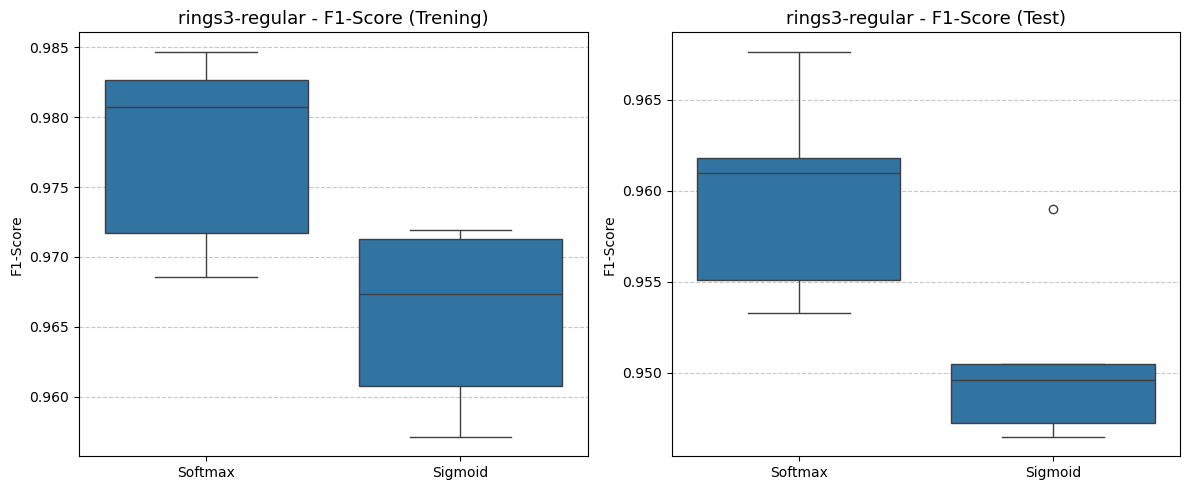

In [74]:
rysuj_boxploty_softmax(df_wyniki, nazwa_zbioru="rings3-regular")

# Dane easy

In [75]:
easy_test = pd.read_csv("mio1/classification/easy-test.csv")
easy_train = pd.read_csv("mio1/classification/easy-training.csv")

X_train = easy_train[['x', 'y']].to_numpy() 
y_train_etykiety = easy_train[['c']].to_numpy().astype(int) 
X_test = easy_test[['x', 'y']].to_numpy()
y_test_etykiety = easy_test[['c']].to_numpy().astype(int)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)

In [76]:
df_wyniki = train_N(X_train, y_train, X_test, y_test, 
                                    N=5, epoki=1000, rozmiar_batcha=64)

tabela_podsumowujaca_softmax(df_wyniki)


Rozpoczynam testy: Softmax
Próba 1/5 | Score Trening: 1.0000 | Score Test: 0.9980
Próba 2/5 | Score Trening: 0.9900 | Score Test: 0.9860
Próba 3/5 | Score Trening: 1.0000 | Score Test: 0.9980
Próba 4/5 | Score Trening: 1.0000 | Score Test: 0.9980
Próba 5/5 | Score Trening: 1.0000 | Score Test: 1.0000

Rozpoczynam testy: Sigmoid
Próba 1/5 | Score Trening: 0.9960 | Score Test: 0.9980
Próba 2/5 | Score Trening: 0.9980 | Score Test: 0.9980
Próba 3/5 | Score Trening: 0.9940 | Score Test: 0.9920
Próba 4/5 | Score Trening: 0.9980 | Score Test: 0.9980
Próba 5/5 | Score Trening: 0.9960 | Score Test: 0.9980


Score_Trening        Score_Test       
                      mean    std       mean    std
Konfiguracja                                       
Sigmoid              0.996  0.002      0.997  0.003
Softmax              0.998  0.004      0.996  0.006

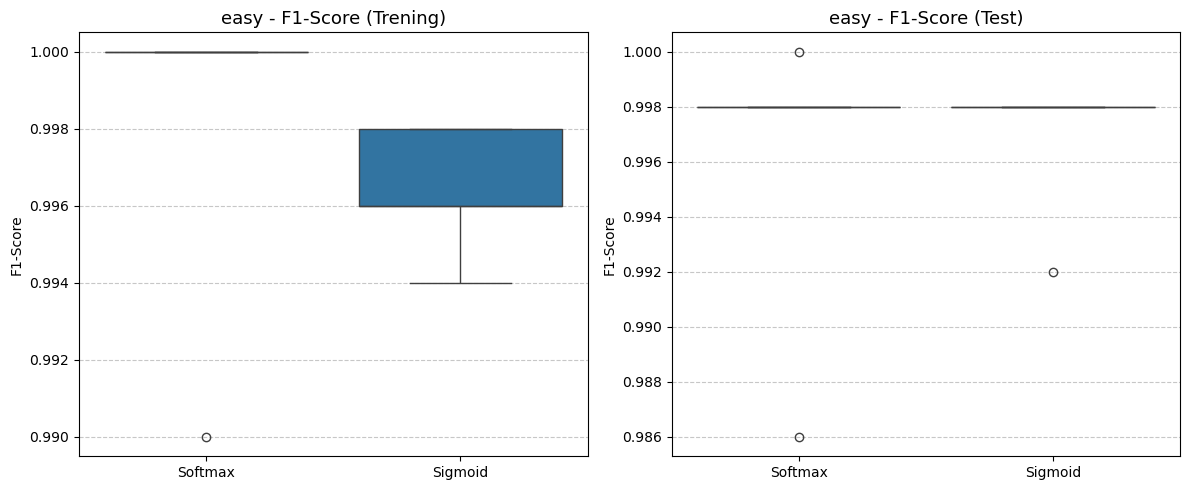

In [77]:
rysuj_boxploty_softmax(df_wyniki, nazwa_zbioru="easy")

# Dane xor3

In [78]:
xor3_test = pd.read_csv("mio1/classification/xor3-test.csv")
xor3_train = pd.read_csv("mio1/classification/xor3-training.csv")

X_train = xor3_train[['x', 'y']].to_numpy() 
y_train_etykiety = xor3_train[['c']].to_numpy().astype(int) 
X_test = xor3_test[['x', 'y']].to_numpy()
y_test_etykiety = xor3_test[['c']].to_numpy().astype(int)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)

In [79]:
df_wyniki = train_N(X_train, y_train, X_test, y_test, 
                                    N=5, epoki=8000, rozmiar_batcha=16)

tabela_podsumowujaca_softmax(df_wyniki)


Rozpoczynam testy: Softmax
Próba 1/5 | Score Trening: 0.9900 | Score Test: 0.9306
Próba 2/5 | Score Trening: 0.9980 | Score Test: 0.9672
Próba 3/5 | Score Trening: 0.9960 | Score Test: 0.9362
Próba 4/5 | Score Trening: 0.9900 | Score Test: 0.9487
Próba 5/5 | Score Trening: 0.9860 | Score Test: 0.9323

Rozpoczynam testy: Sigmoid
Próba 1/5 | Score Trening: 0.9980 | Score Test: 0.9448
Próba 2/5 | Score Trening: 0.9980 | Score Test: 0.9450
Próba 3/5 | Score Trening: 0.9980 | Score Test: 0.9529
Próba 4/5 | Score Trening: 0.9980 | Score Test: 0.9509
Próba 5/5 | Score Trening: 0.9700 | Score Test: 0.9108


Score_Trening        Score_Test       
                      mean    std       mean    std
Konfiguracja                                       
Sigmoid              0.992  0.013      0.941  0.017
Softmax              0.992  0.005      0.943  0.015

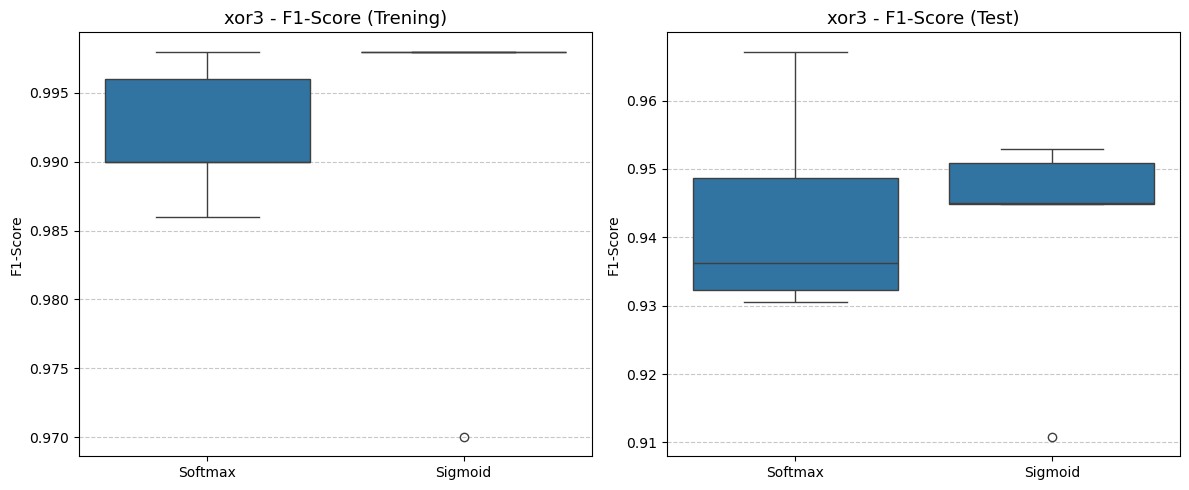

In [80]:
rysuj_boxploty_softmax(df_wyniki, nazwa_zbioru="xor3")